<a href="https://colab.research.google.com/github/Sanhith30/deepLearning-csa4704/blob/main/CO2_Assignment/CO2_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning – Assignment 2 (CO2)
## Complete Python practical notebook (Q1–Q7)

**Course:** CSA47 – Deep Learning  
**Purpose:** Implement the experiments required by the assignment, collect evidence, and explain what the evidence means.

This notebook follows the assignment's sequence: **Predict → Design → Implement → Measure → Analyse → Evaluate → Diagnose → Redesign → Validate**.

### How to use this notebook
1. Run the setup cell first.
2. Run the code and experiment cell under each question in order. Each question saves CSV files and plots in `dl_assignment2_results/`.
3. For a full run, use the final **Run all questions** cell. This may take several minutes on a CPU.
4. Use your own generated CSV values in the written report. Do not copy example values from an earlier run if your rerun differs.

### Dataset and application-context note
The assignment uses real-world contexts (fraud screening, hospital readmission, plant-leaf diagnosis, electricity forecasting, PCB inspection and wildlife camera traps). To keep the notebook self-contained and runnable without downloading large datasets, some sections use public scikit-learn datasets as **methodology proxies**. They demonstrate the requested deep-learning behaviour but are not the actual application datasets. Q4 will automatically use the public UCI Appliances Energy Prediction CSV if `energydata_complete.csv` is placed next to the notebook; otherwise it uses a clearly labelled synthetic time-series proxy.

### Reproducibility
Random seeds: **42, 43 and 44** for repeated experiments, with fixed seed 42 for data splits and gradient checking. Mean and standard deviation across runs are saved where appropriate.

## 0. Environment setup

Required packages: NumPy, pandas, Matplotlib, scikit-learn and PyTorch. Run the install command only if these packages are not already available in your Jupyter environment.

In [1]:
# Uncomment and run if packages are missing:
# %pip install numpy pandas matplotlib scikit-learn torch

import os, random, time, math, copy, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    mean_absolute_error, mean_squared_error
)
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

OUT = "dl_assignment2_results"
os.makedirs(OUT, exist_ok=True)
SEED = 42

def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Benchmark reproducibility is improved by fixed seeds; deterministic kernels
    # are not forced because some hardware operations may not support them.

seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Output folder:", os.path.abspath(OUT))

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, name), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

PyTorch: 2.11.0+cu130
Device: cuda
Output folder: /content/dl_assignment2_results


# Q1 – Hidden Units: Does the Activation Function Matter as the Network Grows Deeper? (6 marks)

### Problem context – Credit-card fraud screening
A bank screens card transactions using tabular features such as transaction amount, time, merchant category and location distance. The development team is comparing **Sigmoid, Tanh and ReLU** as hidden-unit activation functions while increasing network depth.

### What this experiment investigates
- Whether early-layer gradients shrink as depth increases.
- Whether the activation derivative explains the observed gradient behaviour.
- How shallow (2 hidden layers), deep (8 hidden layers) and poor-initialisation edge cases behave.
- Whether ReLU neurons become inactive.
- How training loss and validation accuracy, precision and recall compare.

### Mathematical prediction
For layer \(l\), backpropagation contains the factor

\[
\delta_l = (W_{l+1}^{T}\delta_{l+1})\odot f'(z_l).
\]

The activation derivatives are:

\[
\sigma'(z)=\sigma(z)(1-\sigma(z)),\qquad 0<\sigma'(z)\leq 0.25,
\]
\[
\tanh'(z)=1-\tanh^2(z),\qquad 0\leq\tanh'(z)\leq 1,
\]
\[
\operatorname{ReLU}'(z)=\begin{cases}1,&z>0\\0,&z\leq0.\end{cases}
\]

**Prediction:** Sigmoid is more likely to shrink gradients in deep saturated regions; Tanh may preserve gradients better near zero but also saturates; ReLU preserves gradients along active paths but can produce dead units. He initialisation is the standard starting point for ReLU, while Xavier initialisation is a suitable starting point for Sigmoid/Tanh.

### Dataset and split
The code uses the public Wisconsin Breast Cancer dataset from scikit-learn (569 records, 30 numeric features, binary labels), as a tabular proxy for fraud screening. The stratified split is 60% train (341), 20% validation (114) and 20% test (114). The positive label in this dataset is **benign**, not fraud; the metrics therefore describe this proxy classification task.

In [2]:
# Q1: activation and depth on public binary tabular data
class MLP(nn.Module):
    def __init__(self,d,hidden=64,depth=2,activation="relu",poor_init=None,dropout=0,weight_decay=0):
        super().__init__(); layers=[]; self.linears=[]
        prev=d
        for _ in range(depth):
            lin=nn.Linear(prev,hidden); self.linears.append(lin); layers.append(lin)
            if activation=="sigmoid": layers.append(nn.Sigmoid())
            elif activation=="tanh": layers.append(nn.Tanh())
            else: layers.append(nn.ReLU())
            if dropout: layers.append(nn.Dropout(dropout))
            prev=hidden
        out=nn.Linear(prev,1); self.out=out; layers += [out,nn.Sigmoid()]
        self.net=nn.Sequential(*layers); self.activation=activation; self.poor_init=poor_init
        for lin in self.linears:
            if poor_init=="small": nn.init.normal_(lin.weight,mean=0,std=.01)
            elif poor_init=="large": nn.init.normal_(lin.weight,mean=0,std=2.0)
            elif activation=="relu": nn.init.kaiming_normal_(lin.weight,nonlinearity="relu")
            else: nn.init.xavier_uniform_(lin.weight)
            nn.init.zeros_(lin.bias)
    def forward(self,x): return self.net(x)
def load_bc():
    d=load_breast_cancer()
    Xtr,Xtmp,ytr,ytmp=train_test_split(d.data,d.target,test_size=.4,random_state=SEED,stratify=d.target)
    Xv,Xte,yv,yte=train_test_split(Xtmp,ytmp,test_size=.5,random_state=SEED,stratify=ytmp)
    sc=StandardScaler(); Xtr=sc.fit_transform(Xtr); Xv=sc.transform(Xv); Xte=sc.transform(Xte)
    return (torch.tensor(Xtr,dtype=torch.float32),torch.tensor(ytr[:,None],dtype=torch.float32),
            torch.tensor(Xv,dtype=torch.float32),torch.tensor(yv[:,None],dtype=torch.float32),
            torch.tensor(Xte,dtype=torch.float32),torch.tensor(yte[:,None],dtype=torch.float32))
def grad_norms(model):
    return [float(torch.linalg.vector_norm(l.weight.grad).detach().cpu()) if l.weight.grad is not None else 0 for l in model.linears]
def q1_experiment():
    X,y,Xv,yv,Xte,yte=load_bc(); rows=[]; seed_rows=[]
    configs=[("shallow",2,"relu",None),("deep",8,"sigmoid",None),("deep",8,"tanh",None),
             ("deep",8,"relu",None),("edge_small",8,"relu","small"),("edge_large",8,"relu","large")]
    for seed in [42,43,44]:
      for label,depth,act,init in configs:
        seed_all(seed); model=MLP(X.shape[1],64,depth,act,init).to(DEVICE)
        opt=torch.optim.Adam(model.parameters(),lr=.001); lossfn=nn.BCELoss()
        loader=DataLoader(TensorDataset(X,y),batch_size=32,shuffle=True)
        initial_norm=[]
        for epoch in range(15):
          model.train()
          for xb,yb in loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE); opt.zero_grad(); pred=model(xb); loss=lossfn(pred,yb); loss.backward()
            if epoch==0 and not initial_norm: initial_norm=grad_norms(model)
            opt.step()
        model.eval()
        with torch.no_grad():
          pv=model(Xv.to(DEVICE)).cpu().numpy().ravel(); pte=model(Xte.to(DEVICE)).cpu().numpy().ravel()
          trpred=model(X.to(DEVICE)).cpu().numpy().ravel()
        dead=np.nan
        if act=="relu":
          with torch.no_grad():
            acts=[]; z=X.to(DEVICE)
            for layer in model.net:
              z=layer(z)
              if isinstance(layer,nn.ReLU): acts.append((z<=0).all(dim=0).float().mean().item())
            dead=float(np.mean(acts)) if acts else np.nan
        row=dict(seed=seed,configuration=label,depth=depth,activation=act,initialisation=init or "activation_default",
          train_loss=float(np.mean(-(y.numpy().ravel()*np.log(np.clip(trpred,1e-8,1-1e-8))+(1-y.numpy().ravel())*np.log(np.clip(1-trpred,1e-8,1-1e-8))))),val_accuracy=accuracy_score(yv.numpy().ravel(),pv>=.5),
          val_precision=precision_score(yv.numpy().ravel(),pv>=.5,zero_division=0),
          val_recall=recall_score(yv.numpy().ravel(),pv>=.5,zero_division=0),relu_inactive_fraction=dead)
        rows.append(row)
        config_key=label+"_"+act+("_"+init if init else "")
        for i,n in enumerate(initial_norm): seed_rows.append(dict(seed=seed,configuration=config_key,layer=i+1,gradient_norm=n))
    pd.DataFrame(rows).to_csv(os.path.join(OUT,"q1_activation_results.csv"),index=False)
    pd.DataFrame(seed_rows).to_csv(os.path.join(OUT,"q1_gradient_norms.csv"),index=False)
    df=pd.DataFrame(seed_rows)
    if not df.empty:
      plt.figure(figsize=(8,4))
      for cfg,g in df.groupby("configuration"): plt.plot(g.groupby("layer").gradient_norm.mean().index,g.groupby("layer").gradient_norm.mean().values,marker="o",label=cfg)
      plt.yscale("log"); plt.xlabel("Hidden layer (1 = earliest)"); plt.ylabel("Gradient L2 norm (epoch 1)"); plt.legend(fontsize=7); savefig("q1_gradient_norms.png")
    print("\nQ1 results saved.")

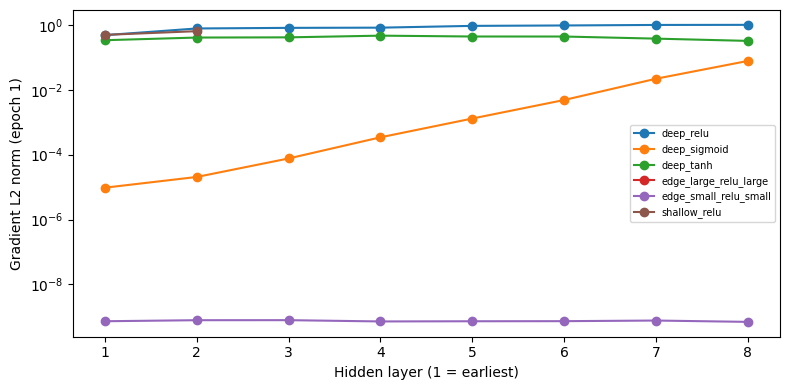


Q1 results saved.


train_loss  val_accuracy  \
configuration activation initialisation                                 
deep          relu       activation_default      0.0008        0.9649   
              sigmoid    activation_default      0.1645        0.9649   
              tanh       activation_default      0.0316        0.9766   
edge_large    relu       large                   8.4631        0.5439   
edge_small    relu       small                   0.0386        0.9737   
shallow       relu       activation_default      0.0517        0.9737   

                                             val_precision  val_recall  \
configuration activation initialisation                                  
deep          relu       activation_default         0.9812      0.9630   
              sigmoid    activation_default         0.9767      0.9676   
              tanh       activation_default         0.9952      0.9676   
edge_large    relu       large                      0.4211      0.6667   
edge_small    relu       small                      1.0000      0.9583   
shallow       relu       activation_default         0.9952      0.9630   

                                             relu_inactive_fraction  
configuration activation initialisation                              
deep          relu       activation_default                  0.1029  
              sigmoid    activation_default                     NaN  
              tanh       activation_default                     NaN  
edge_large    relu       large                               0.0599  
edge_small    relu       small                               0.2806  
shallow       relu       activation_default                  0.0026

configuration,deep_relu,deep_sigmoid,deep_tanh,edge_large_relu_large,edge_small_relu_small,shallow_relu
layer,,,,,,
1,0.482112,0.000010,0.336725,0.0,0.0,0.491364
2,0.774569,0.000021,0.406522,0.0,0.0,0.639533
3,0.808416,0.000076,0.412325,0.0,0.0,NaN
4,0.820276,0.000343,0.465080,0.0,0.0,NaN
5,0.931022,0.001299,0.437825,0.0,0.0,NaN
6,0.958384,0.004836,0.437217,0.0,0.0,NaN
7,0.994578,0.021869,0.376534,0.0,0.0,NaN
8,1.001124,0.077396,0.320709,0.0,0.0,NaN


In [3]:
# Run Q1: 3 random seeds; shallow, deep activation and initialisation edge cases.
q1_experiment()

# Display the saved summary tables.
q1_results = pd.read_csv(os.path.join(OUT, "q1_activation_results.csv"))
q1_gradient_results = pd.read_csv(os.path.join(OUT, "q1_gradient_norms.csv"))
display(q1_results.groupby(["configuration", "activation", "initialisation"], dropna=False)
        .agg({"train_loss":"mean", "val_accuracy":"mean", "val_precision":"mean",
              "val_recall":"mean", "relu_inactive_fraction":"mean"}).round(4))
display(q1_gradient_results.groupby(["configuration", "layer"]).gradient_norm.mean().unstack(0).round(6))

### How to interpret Q1
- Compare the gradient norms in layer 1 (the earliest hidden layer) with those in later hidden layers. A very small early-layer norm indicates weak gradient flow.
- `relu_inactive_fraction` is the fraction of hidden ReLU units that are inactive for every record in the training split at evaluation time.
- Compare validation precision and recall, not accuracy alone. In a real fraud task, the rare fraud class must be treated as the positive class and class imbalance must be handled explicitly.
- The network must contain at least eight hidden layers for the bank's production constraint. Treat the observed results as a recommendation for further validation on actual transaction data, not proof that one activation is universally best.

# Q2 – Can You Trust Your Gradients? Backpropagation from First Principles (4 marks)

### Problem context – Hospital readmission prediction
A hospital analytics team wants to predict whether a patient will be readmitted within 30 days. The four example inputs are **age, length of stay, number of prior admissions and number of medications**.

### What this experiment investigates
Implement a one-hidden-layer feedforward network with a sigmoid output and binary cross-entropy. The forward pass, backward pass, parameter update and gradient checking are implemented using **NumPy only**. No automatic differentiation is used.

### Mathematical derivation
For a mini-batch of \(m\) cases:

\[
Z_1=XW_1+b_1,\quad H=\sigma(Z_1),\quad Z_2=HW_2+b_2,\quad P=\sigma(Z_2).
\]

\[
L=-\frac{1}{m}\sum_{i=1}^{m}\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right].
\]

For sigmoid output + binary cross-entropy:

\[
\frac{\partial L}{\partial Z_2}=\frac{P-Y}{m},\quad
\frac{\partial L}{\partial W_2}=H^T\frac{P-Y}{m},\quad
\frac{\partial L}{\partial b_2}=\sum_i\frac{P_i-Y_i}{m}.
\]

\[
\delta_1=\left(\frac{P-Y}{m}W_2^T\right)\odot H\odot(1-H),
\]
\[
\frac{\partial L}{\partial W_1}=X^T\delta_1,\qquad
\frac{\partial L}{\partial b_1}=\sum_i\delta_{1,i}.
\]

The parameter update is \(\theta\leftarrow\theta-\eta\nabla_\theta L\).

**Gradient check:** central finite differences approximate one parameter derivative as

\[
g_{num}=\frac{L(\theta+\epsilon)-L(\theta-\epsilon)}{2\epsilon}.
\]

The relative error is

\[
E_{rel}=\frac{\|g_{analytic}-g_{num}\|_2}
{\|g_{analytic}\|_2+\|g_{num}\|_2+10^{-12}}.
\]

The code checks every parameter group \(W_1,b_1,W_2,b_2\) with \(\epsilon=10^{-5}\) and \(10^{-6}\), then removes a hidden sigmoid derivative deliberately to demonstrate bug detection.

**Dataset note:** the executable training demonstration uses the first four standardised numeric features from the 569-row Wisconsin Breast Cancer dataset as a public tabular proxy because a hospital readmission dataset is not bundled. The implementation's four-feature input shape matches the problem setup, but the labels are benign/malignant, not readmission.

In [4]:
# Q2: NumPy-only backpropagation and central finite differences
def sigmoid_np(x):
    x=np.clip(x,-40,40)
    return 1/(1+np.exp(-x))
def numpy_forward(X, W1,b1,W2,b2):
    H=sigmoid_np(X@W1+b1); P=sigmoid_np(H@W2+b2)
    return H,P
def bce_np(Y,P):
    P=np.clip(P,1e-12,1-1e-12)
    return -np.mean(Y*np.log(P)+(1-Y)*np.log(1-P))
def numpy_grads(X,Y,params,bug=False):
    W1,b1,W2,b2=params
    H,P=numpy_forward(X,W1,b1,W2,b2); m=len(X)
    dZ2=(P-Y)/m
    dW2=H.T@dZ2; db2=np.sum(dZ2,axis=0,keepdims=True)
    dH=dZ2@W2.T
    dZ1=dH if bug else dH*H*(1-H)
    dW1=X.T@dZ1; db1=np.sum(dZ1,axis=0,keepdims=True)
    return [dW1,db1,dW2,db2]
def gradient_check():
    rng=np.random.default_rng(7)
    X=rng.normal(size=(7,4)); Y=rng.integers(0,2,size=(7,1)).astype(float)
    params=[rng.normal(scale=.2,size=(4,5)),rng.normal(scale=.1,size=(1,5)),
            rng.normal(scale=.2,size=(5,1)),rng.normal(scale=.1,size=(1,1))]
    rows=[]
    for bug in [False,True]:
      ana=numpy_grads(X,Y,params,bug=bug)
      for eps in [1e-5,1e-6]:
       for group,(p,g) in enumerate(zip(params,ana)):
        num=np.zeros_like(p)
        for ix in np.ndindex(p.shape):
          old=p[ix]; p[ix]=old+eps; lp=bce_np(Y,numpy_forward(X,*params)[1])
          p[ix]=old-eps; lm=bce_np(Y,numpy_forward(X,*params)[1]); p[ix]=old
          num[ix]=(lp-lm)/(2*eps)
        rel=np.linalg.norm(g-num)/(np.linalg.norm(g)+np.linalg.norm(num)+1e-12)
        rows.append(dict(buggy_backward=bug,epsilon=eps,parameter=["W1","b1","W2","b2"][group],relative_error=rel))
    pd.DataFrame(rows).to_csv(os.path.join(OUT,"q2_gradient_check.csv"),index=False)
    print("\nQ2 gradient check:\n",pd.DataFrame(rows).to_string(index=False))
    # NumPy-only training on four standardized features from the public Breast Cancer dataset.
    Xtr,ytr,Xv,yv,Xte,yte=load_bc()
    Xtr=Xtr.numpy()[:,:4].astype(np.float64); Xv=Xv.numpy()[:,:4].astype(np.float64); Xte=Xte.numpy()[:,:4].astype(np.float64)
    ytr=ytr.numpy().astype(np.float64); yv=yv.numpy().astype(np.float64); yte=yte.numpy().astype(np.float64)
    train_rows=[]; summary_rows=[]; lr=.05; d=4; h=8
    for seed in [42,43,44]:
      rng=np.random.default_rng(seed)
      params=[rng.normal(0,.15,(d,h)),np.zeros((1,h)),rng.normal(0,.15,(h,1)),np.zeros((1,1))]
      for epoch in range(1,501):
        H,P=numpy_forward(Xtr,*params); loss=bce_np(ytr,P)
        grads=numpy_grads(Xtr,ytr,params)
        params=[par-lr*g for par,g in zip(params,grads)]
        if epoch in [1,5,10,25,50,100,200,300,400,500]:
            _,pval=numpy_forward(Xv,*params)
            train_rows.append(dict(seed=seed,epoch=epoch,train_bce=loss,val_bce=bce_np(yv,pval),
                train_accuracy=accuracy_score(ytr.ravel(),P.ravel()>=.5),val_accuracy=accuracy_score(yv.ravel(),pval.ravel()>=.5)))
      ptr=numpy_forward(Xtr,*params)[1]; pval=numpy_forward(Xv,*params)[1]; ptest=numpy_forward(Xte,*params)[1]
      summary_rows.append(dict(seed=seed,dataset="sklearn Breast Cancer Wisconsin (first 4 standardized features)",rows=569,
        train_rows=len(ytr),validation_rows=len(yv),test_rows=len(yte),hidden_units=h,epochs=500,learning_rate=lr,
        train_accuracy=accuracy_score(ytr.ravel(),ptr.ravel()>=.5),validation_accuracy=accuracy_score(yv.ravel(),pval.ravel()>=.5),
        test_accuracy=accuracy_score(yte.ravel(),ptest.ravel()>=.5),test_bce=bce_np(yte,ptest)))
    train_df=pd.DataFrame(train_rows); sum_df=pd.DataFrame(summary_rows)
    train_df.to_csv(os.path.join(OUT,"q2_numpy_training_curve.csv"),index=False)
    sum_df.to_csv(os.path.join(OUT,"q2_numpy_training_summary.csv"),index=False)
    agg=sum_df[["train_accuracy","validation_accuracy","test_accuracy","test_bce"]].agg(["mean","std"]).T
    agg.to_csv(os.path.join(OUT,"q2_numpy_training_aggregate.csv"))
    print("NumPy-only training runs:\\n",sum_df.round(4).to_string(index=False))
    print("Training mean/std:\\n",agg.round(4).to_string())

In [5]:
# Run Q2: analytical vs numerical gradients, buggy-gradient demonstration,
# and NumPy-only binary-classification training over three seeds.
gradient_check()

grad_check = pd.read_csv(os.path.join(OUT, "q2_gradient_check.csv"))
q2_train = pd.read_csv(os.path.join(OUT, "q2_numpy_training_summary.csv"))
print("Gradient-check relative errors:")
display(grad_check.pivot_table(index=["buggy_backward", "parameter"],
                               columns="epsilon", values="relative_error").round(10))
print("NumPy training summary:")
display(q2_train.round(4))


Q2 gradient check:
  buggy_backward  epsilon parameter  relative_error
          False 0.000010        W1    3.319988e-10
          False 0.000010        b1    2.297381e-10
          False 0.000010        W2    4.127400e-11
          False 0.000010        b2    3.704433e-12
          False 0.000001        W1    3.088239e-09
          False 0.000001        b1    9.022106e-09
          False 0.000001        W2    1.676180e-10
          False 0.000001        b2    3.825897e-10
           True 0.000010        W1    6.222739e-01
           True 0.000010        b1    6.412649e-01
           True 0.000010        W2    4.127400e-11
           True 0.000010        b2    3.704433e-12
           True 0.000001        W1    6.222739e-01
           True 0.000001        b1    6.412649e-01
           True 0.000001        W2    1.676180e-10
           True 0.000001        b2    3.825897e-10
NumPy-only training runs:\n  seed                                                         dataset  rows  train_r

epsilon                       0.000001      0.000010
buggy_backward parameter                            
False          W1         3.100000e-09  3.000000e-10
               W2         2.000000e-10  0.000000e+00
               b1         9.000000e-09  2.000000e-10
               b2         4.000000e-10  0.000000e+00
True           W1         6.222739e-01  6.222739e-01
               W2         2.000000e-10  0.000000e+00
               b1         6.412649e-01  6.412649e-01
               b2         4.000000e-10  0.000000e+00

NumPy training summary:


,seed,dataset,rows,train_rows,validation_rows,test_rows,hidden_units,epochs,learning_rate,train_accuracy,validation_accuracy,test_accuracy,test_bce
0,42,sklearn Breast Cancer Wisconsin (first 4 stand...,569,341,114,114,8,500,0.05,0.8974,0.8947,0.8596,0.3425
1,43,sklearn Breast Cancer Wisconsin (first 4 stand...,569,341,114,114,8,500,0.05,0.8974,0.8947,0.8596,0.3349
2,44,sklearn Breast Cancer Wisconsin (first 4 stand...,569,341,114,114,8,500,0.05,0.8944,0.8860,0.8509,0.3630


### How to interpret Q2
- Correct analytical gradients should have small relative error (often less than \(10^{-6}\) to \(10^{-4}\) in float64 for this small, well-conditioned example).
- In the deliberately buggy pass, the missing \(H(1-H)\) derivative affects the first-layer groups \(W_1\) and \(b_1\) first. The output-layer groups \(W_2\) and \(b_2\) should remain correct because their derivatives are not changed.
- Use the actual relative errors printed by your run when writing the final report.

# Q3 – Engineer Overfitting, Then Control It: Regularisation (6 marks)

### Problem context – Plant-leaf disease detection on a small dataset
An agricultural start-up has only a few hundred labelled images of healthy and diseased leaves. A large network may obtain high training accuracy but poor performance on new field images.

### What this experiment investigates
The notebook compares one generalisation-oriented condition, an intentionally overfit condition, and a label-noise condition. It then compares **L2 weight decay, Dropout, Early Stopping, Label Smoothing**, and a combined L2 + Dropout strategy. These satisfy the assignment's requirement to compare at least four regularisation approaches.

### Prediction before implementation
A large-capacity model trained on a small subset should have a larger training–validation gap (higher variance). A smaller model trained on more data should generally have a smaller gap but may have higher bias. Label noise makes the training labels less reliable and may encourage memorisation.

### Dataset and split
The executable demonstration uses the public scikit-learn Digits dataset (1,797 8×8 grayscale images; 10 classes), split stratified 60% train (1,078), 20% validation (359) and 20% test (360). This is a lightweight image-classification proxy, not a plant-leaf dataset. A real leaf-disease submission should repeat this experiment with the approved leaf-image dataset and label-preserving augmentation.

### Metrics
The code records train/validation loss curves, train and validation accuracy, accuracy gap, epoch of minimum validation loss, test accuracy and the L2 norm of learned weights. It saves per-run and mean/std aggregate CSVs.

In [6]:
# Q3 regularization / data-size / label noise on Digits
def load_digits_data(resize=8):
    d=load_digits(); X=d.images.astype(np.float32)/16.; y=d.target.astype(np.int64)
    Xtr,Xtmp,ytr,ytmp=train_test_split(X,y,test_size=.4,random_state=SEED,stratify=y)
    Xv,Xte,yv,yte=train_test_split(Xtmp,ytmp,test_size=.5,random_state=SEED,stratify=ytmp)
    def tensor(x): return torch.tensor(x[:,None,:,:],dtype=torch.float32)
    return tensor(Xtr),torch.tensor(ytr),tensor(Xv),torch.tensor(yv),tensor(Xte),torch.tensor(yte)
class DigitsMLP(nn.Module):
    def __init__(self,widths=(64,),drop=0):
        super().__init__(); seq=[]; prev=64
        for w in widths: seq += [nn.Linear(prev,w),nn.ReLU(),nn.Dropout(drop)]; prev=w
        seq += [nn.Linear(prev,10)]; self.net=nn.Sequential(*seq)
    def forward(self,x): return self.net(x.flatten(1))
def q3_experiment():
    X,y,Xv,yv,Xte,yte=load_digits_data()
    X=X.flatten(1); Xv=Xv.flatten(1); Xte=Xte.flatten(1)
    rows=[]; curves=[]
    conditions=[("generalises",.60,(64,),0,0.,0.0,0.0,False),
                ("overfit",.10,(128,128,64),0,0.,0.0,0.0,False),
                ("label_noise",.10,(128,128,64),0,0.,.15,0.0,False),
                ("l2",.10,(128,128,64),0,1e-3,0.0,0.0,False),
                ("dropout",.10,(128,128,64),.5,0.,0.0,0.0,False),
                ("early_stopping",.10,(128,128,64),0,0.,0.0,0.0,True),
                ("label_smoothing",.10,(128,128,64),0,0.,0.0,0.1,False),
                ("l2_dropout",.10,(128,128,64),.3,1e-3,0.0,0.0,False)]
    for seed in [42,43,44]:
      for ci,(name,frac,widths,drop,wd,noise,smoothing,early_stop) in enumerate(conditions):
        seed_all(seed); rng=np.random.default_rng(seed*100+ci)
        n=max(30,int(len(X)*frac)); idx=rng.choice(len(X),n,replace=False); xx=X[idx].clone(); yy=y[idx].clone()
        if noise:
          k=int(len(yy)*noise); ix=rng.choice(len(yy),k,replace=False)
          offsets=torch.tensor(rng.integers(1,10,k),dtype=torch.long)
          yy[ix]=(yy[ix]+offsets)%10  # guaranteed to change each selected label
        model=DigitsMLP(widths,drop).to(DEVICE); opt=torch.optim.Adam(model.parameters(),lr=.001,weight_decay=wd)
        loader=DataLoader(TensorDataset(xx,yy),batch_size=32,shuffle=True); best=1e9; best_ep=0; best_state=None; bad_epochs=0; epochs_run=0
        for ep in range(1,61):
          epochs_run=ep; model.train()
          for xb,yb in loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE); opt.zero_grad(); loss=nn.functional.cross_entropy(model(xb),yb,label_smoothing=smoothing); loss.backward(); opt.step()
          model.eval()
          with torch.no_grad():
            trloss=nn.functional.cross_entropy(model(xx.to(DEVICE)),yy.to(DEVICE)).item()
            valloss=nn.functional.cross_entropy(model(Xv.to(DEVICE)),yv.to(DEVICE)).item()
            tracc=(model(xx.to(DEVICE)).argmax(1).cpu()==yy).float().mean().item()
            vacc=(model(Xv.to(DEVICE)).argmax(1).cpu()==yv).float().mean().item()
          curves.append(dict(seed=seed,condition=name,epoch=ep,train_loss=trloss,val_loss=valloss,train_accuracy=tracc,val_accuracy=vacc))
          if valloss<best:
            best=valloss; best_ep=ep; best_state=copy.deepcopy(model.state_dict()); bad_epochs=0
          else: bad_epochs+=1
          if early_stop and bad_epochs>=5: break
        # Evaluate every condition at its own best-validation checkpoint for a fair comparison.
        model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
          testacc=(model(Xte.to(DEVICE)).argmax(1).cpu()==yte).float().mean().item()
          trainacc=(model(xx.to(DEVICE)).argmax(1).cpu()==yy).float().mean().item()
          valacc=(model(Xv.to(DEVICE)).argmax(1).cpu()==yv).float().mean().item()
        norm=math.sqrt(sum(float((par.detach()**2).sum()) for pname,par in model.named_parameters() if "weight" in pname))
        rows.append(dict(seed=seed,condition=name,best_val_loss=best,best_epoch=best_ep,epochs_run=epochs_run,
                         train_accuracy=trainacc,val_accuracy=valacc,accuracy_gap=trainacc-valacc,
                         test_accuracy=testacc,weight_l2_norm=norm))
    df=pd.DataFrame(rows); df.to_csv(os.path.join(OUT,"q3_regularization_summary.csv"),index=False)
    agg=df.groupby("condition").agg({c:["mean","std"] for c in ["best_val_loss","best_epoch","epochs_run","train_accuracy","val_accuracy","accuracy_gap","test_accuracy","weight_l2_norm"]})
    agg.columns=["_".join(c) for c in agg.columns]; agg.reset_index().to_csv(os.path.join(OUT,"q3_regularization_aggregate.csv"),index=False)
    cdf=pd.DataFrame(curves); cdf.to_csv(os.path.join(OUT,"q3_learning_curves.csv"),index=False)
    for metric in ["loss","accuracy"]:
      plt.figure(figsize=(8,4))
      cmean=cdf.groupby(["condition","epoch"])[["train_"+metric,"val_"+metric]].mean().reset_index()
      for name,g in cmean.groupby("condition"):
        plt.plot(g.epoch,g["train_"+metric],linestyle="--",alpha=.6)
        plt.plot(g.epoch,g["val_"+metric],label=name)
      plt.xlabel("Epoch"); plt.ylabel(metric); plt.legend(fontsize=7,ncol=2); savefig("q3_"+metric+"_curves.png")
    print("\nQ3 aggregate results:\n",agg.round(4).to_string())

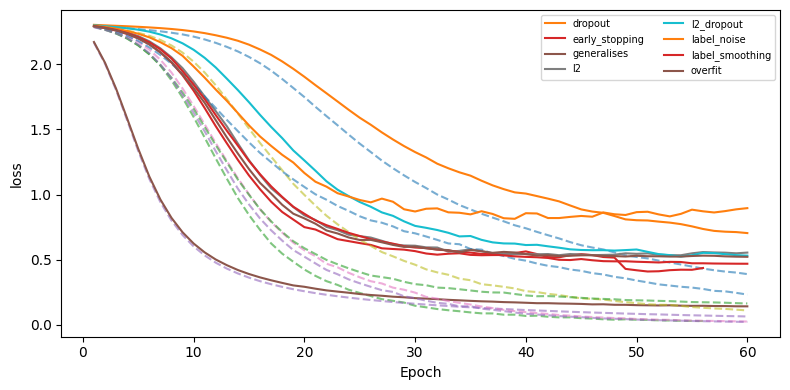

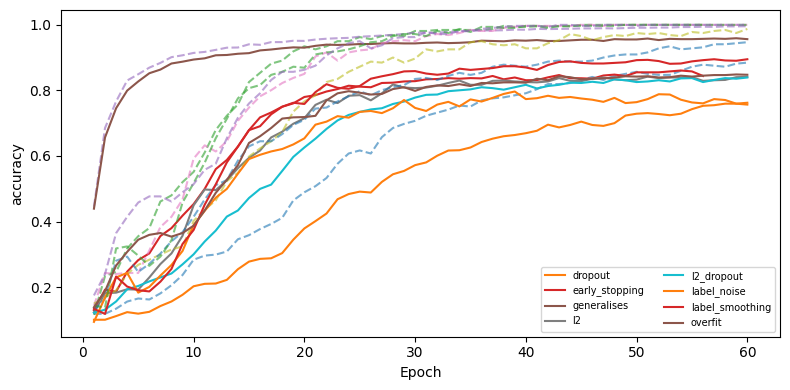


Q3 aggregate results:
                  best_val_loss_mean  best_val_loss_std  best_epoch_mean  best_epoch_std  epochs_run_mean  epochs_run_std  train_accuracy_mean  train_accuracy_std  val_accuracy_mean  val_accuracy_std  accuracy_gap_mean  accuracy_gap_std  test_accuracy_mean  test_accuracy_std  weight_l2_norm_mean  weight_l2_norm_std
condition                                                                                                                                                                                                                                                                                                                  
dropout                      0.6992             0.1808          59.0000          1.7321             60.0             0.0               0.8785              0.0809             0.7586            0.1001             0.1199            0.0288              0.7546             0.0863              13.3921              0.2535
early_stopping              

,condition,best_val_loss_mean,best_val_loss_std,best_epoch_mean,best_epoch_std,epochs_run_mean,epochs_run_std,train_accuracy_mean,train_accuracy_std,val_accuracy_mean,val_accuracy_std,accuracy_gap_mean,accuracy_gap_std,test_accuracy_mean,test_accuracy_std,weight_l2_norm_mean,weight_l2_norm_std
0,dropout,0.6992,0.1808,59.0000,1.7321,60.0,0.0,0.8785,0.0809,0.7586,0.1001,0.1199,0.0288,0.7546,0.0863,13.3921,0.2535
1,early_stopping,0.5147,0.0955,43.0000,8.0000,48.0,8.0,0.9938,0.0054,0.8496,0.0056,0.1442,0.0028,0.8315,0.0085,14.3571,0.3180
2,generalises,0.1422,0.0102,59.3333,0.5774,60.0,0.0,0.9954,0.0015,0.9601,0.0113,0.0353,0.0097,0.9583,0.0056,13.7739,0.2616
3,l2,0.5174,0.1033,39.0000,8.7178,60.0,0.0,0.9813,0.0247,0.8319,0.0417,0.1494,0.0172,0.8213,0.0489,12.0793,0.3634
4,l2_dropout,0.5096,0.0785,57.0000,2.6458,60.0,0.0,0.9813,0.0000,0.8394,0.0336,0.1419,0.0336,0.8065,0.0042,12.3447,0.0860
5,label_noise,0.7919,0.2889,37.0000,6.5574,60.0,0.0,0.8785,0.0187,0.7837,0.0727,0.0948,0.0545,0.7870,0.0709,13.7236,0.5042
6,label_smoothing,0.4655,0.0096,58.3333,1.5275,60.0,0.0,1.0000,0.0000,0.8951,0.0043,0.1049,0.0043,0.8815,0.0258,13.9041,0.0478
7,overfit,0.5016,0.0178,45.3333,12.6623,60.0,0.0,0.9938,0.0108,0.8496,0.0201,0.1442,0.0144,0.8509,0.0143,14.4185,0.4166


In [7]:
# Run Q3: three seeds, generalisation/overfit/label-noise and regularisation conditions.
q3_experiment()
q3_summary = pd.read_csv(os.path.join(OUT, "q3_regularization_aggregate.csv"))
q3_curves = pd.read_csv(os.path.join(OUT, "q3_learning_curves.csv"))
display(q3_summary.round(4))

### How to interpret Q3
- A regulariser is useful when it reduces the validation gap or improves validation/test performance, not merely when it lowers training accuracy.
- L2 penalises large weights; Dropout reduces co-adaptation; Early Stopping restores the checkpoint with the lowest validation loss; Label Smoothing discourages overconfident outputs.
- Compare the combination with the individual methods. A combination can help, have no effect, or over-regularise and underfit.
- The notebook restores the best-validation checkpoint for each regularisation condition before final evaluation, so comparisons use the selected checkpoint rather than an arbitrary last epoch.

# Q4 – Optimisation for Training Deep Models: Which Optimiser, Under Which Conditions? (6 marks)

### Problem context – Electricity demand forecasting
A power-distribution company forecasts next-hour electricity demand from weather, calendar and recent-load features. Nightly retraining has a fixed training budget, so the optimiser must reach a useful validation error reliably.

### Optimisers compared
- **SGD:** \(\theta_{t+1}=\theta_t-\eta g_t\)
- **Momentum:** \(v_t=\beta v_{t-1}+g_t;\quad\theta_{t+1}=\theta_t-\eta v_t\)
- **RMSProp:** \(s_t=\rho s_{t-1}+(1-\rho)g_t^2;\quad\theta_{t+1}=\theta_t-\eta g_t/(\sqrt{s_t}+\epsilon)\)
- **Adam:** exponential first and second moments with bias correction:

\[
m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\quad
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2,
\]
\[
\hat m_t=\frac{m_t}{1-\beta_1^t},\quad
\hat v_t=\frac{v_t}{1-\beta_2^t},\quad
\theta_{t+1}=\theta_t-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.
\]

### Experimental design
The same feedforward forecasting network is trained using 4 optimisers, 3 learning rates (0.0001, 0.001, 0.01), 2 batch sizes (32, 128), and 3 random seeds. The run uses a 20-epoch budget and a predeclared normalised validation MSE target of 0.20. Chronological 70/15/15 splitting prevents future records from leaking into training.

### Dataset note
If `energydata_complete.csv` (the UCI Appliances Energy Prediction dataset file) is placed in the notebook folder, the code uses it and aggregates records hourly. The target is appliance energy use, a proxy for load forecasting rather than utility-grid demand. If the file is absent, a seeded synthetic hourly series is used and explicitly labelled in `q4_dataset_metadata.json`. Do not report synthetic results as UCI results.

In [8]:
# Q4 synthetic chronological electricity forecasting
class ForecastNet(nn.Module):
    def __init__(self,d):
        super().__init__(); self.net=nn.Sequential(nn.Linear(d,64),nn.ReLU(),nn.Linear(64,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self,x): return self.net(x)
def q4_experiment():
    # Prefer the public UCI appliance-energy file when the user downloads it next to this script.
    # In the present run the file was unavailable, so a seeded synthetic hourly series is used as a transparent proxy.
    csv_path="energydata_complete.csv"  # looked up in the notebook working directory
    rows=[]; curve_rows=[]
    if os.path.exists(csv_path):
      raw=pd.read_csv(csv_path)
      raw["date"]=pd.to_datetime(raw["date"])
      hourly=raw.set_index("date").resample("h").agg({"Appliances":"sum","T1":"mean","RH_1":"mean","T2":"mean","RH_2":"mean","T_out":"mean","Windspeed":"mean"}).dropna()
      t=np.arange(len(hourly)); demand=hourly["Appliances"].to_numpy(dtype=float)
      hr=hourly.index.hour.to_numpy(); dow=hourly.index.dayofweek.to_numpy()
      feats=np.column_stack([np.sin(2*np.pi*hr/24),np.cos(2*np.pi*hr/24),np.sin(2*np.pi*dow/7),np.cos(2*np.pi*dow/7),
          hourly["T1"].to_numpy(),hourly["RH_1"].to_numpy(),hourly["T2"].to_numpy(),hourly["RH_2"].to_numpy(),
          hourly["T_out"].to_numpy(),hourly["Windspeed"].to_numpy(),np.roll(demand,1),np.roll(demand,2)])
      feats=feats[2:-1]; target=demand[3:]
      dataset_name="UCI Appliances Energy Prediction, hourly aggregation"
      raw_rows=len(raw); series_rows=len(hourly)
    else:
      rng=np.random.default_rng(SEED); n=400; t=np.arange(n)
      temp=20+8*np.sin(2*np.pi*t/(24*365))+rng.normal(0,2,n)
      demand=100+15*np.sin(2*np.pi*t/24)+8*np.sin(2*np.pi*t/(24*7))+0.7*temp+rng.normal(0,3,n)
      feats=np.column_stack([np.sin(2*np.pi*t/24),np.cos(2*np.pi*t/24),np.sin(2*np.pi*t/(24*7)),
                            np.cos(2*np.pi*t/(24*7)),temp,np.roll(demand,1),np.roll(demand,2)])
      feats=feats[2:-1]; target=demand[3:]
      dataset_name="Seeded synthetic hourly demand proxy (UCI file not present)"
      raw_rows=n; series_rows=n
    n=len(target); a=int(.7*n); b=int(.85*n)
    Xtr,Xv,Xte=feats[:a],feats[a:b],feats[b:]; ytr,yv,yte=target[:a],target[a:b],target[b:]
    with open(os.path.join(OUT,"q4_dataset_metadata.json"),"w") as mf:
      json.dump({"dataset":dataset_name,"raw_rows":raw_rows,"hourly_rows":series_rows,"forecast_windows":len(target),
        "train_rows":len(ytr),"validation_rows":len(yv),"test_rows":len(yte),"split":"chronological 70/15/15",
        "seed":SEED,"public_file_used":os.path.exists(csv_path)},mf,indent=2)
    mu=Xtr.mean(0); sd=Xtr.std(0)+1e-8; Xtr=(Xtr-mu)/sd; Xv=(Xv-mu)/sd; Xte=(Xte-mu)/sd
    ym=ytr.mean(); ys=ytr.std()+1e-8; ytr=(ytr-ym)/ys; yv_s=(yv-ym)/ys
    optimizers=["SGD","Momentum","RMSprop","Adam"]
    for seed in [42,43,44]:
      for bs in [32,128]:
       for lr in [.0001,.001,.01]:
        for oname in optimizers:
          seed_all(seed); model=ForecastNet(Xtr.shape[1]).to(DEVICE)
          if oname=="SGD": opt=torch.optim.SGD(model.parameters(),lr=lr)
          elif oname=="Momentum": opt=torch.optim.SGD(model.parameters(),lr=lr,momentum=.9)
          elif oname=="RMSprop": opt=torch.optim.RMSprop(model.parameters(),lr=lr)
          else: opt=torch.optim.Adam(model.parameters(),lr=lr)
          ds=TensorDataset(torch.tensor(Xtr,dtype=torch.float32),torch.tensor(ytr[:,None],dtype=torch.float32))
          loader=DataLoader(ds,batch_size=bs,shuffle=False); reached=None; losses=[]; diverged=False
          for ep in range(1,21):
            model.train()
            for xb,yb in loader:
              xb,yb=xb.to(DEVICE),yb.to(DEVICE); opt.zero_grad(); pred=model(xb); loss=nn.functional.mse_loss(pred,yb); loss.backward(); opt.step()
            model.eval()
            with torch.no_grad(): vl=nn.functional.mse_loss(model(torch.tensor(Xv,dtype=torch.float32,device=DEVICE)),torch.tensor(yv_s[:,None],dtype=torch.float32,device=DEVICE)).item()
            losses.append(vl)
            curve_rows.append(dict(seed=seed,optimizer=oname,learning_rate=lr,batch_size=bs,epoch=ep,val_mse=vl))
            if not np.isfinite(vl) or vl>1e4: diverged=True; break
            if reached is None and vl<=.20: reached=ep
          with torch.no_grad(): pred=model(torch.tensor(Xte,dtype=torch.float32,device=DEVICE)).cpu().numpy().ravel()*ys+ym
          rmse=float(np.sqrt(mean_squared_error(yte,pred))); mae=float(mean_absolute_error(yte,pred))
          rows.append(dict(seed=seed,optimizer=oname,learning_rate=lr,batch_size=bs,epochs_run=len(losses),
            epochs_to_target=reached if reached is not None else np.nan,final_val_mse=losses[-1],test_rmse=rmse,test_mae=mae,
            diverged=diverged,loss_oscillation_std=float(np.std(np.diff(losses))) if len(losses)>2 else np.nan))
    df=pd.DataFrame(rows); df.to_csv(os.path.join(OUT,"q4_optimizer_results.csv"),index=False)
    agg=df.groupby(["optimizer","learning_rate","batch_size"]).agg({c:["mean","std"] for c in ["epochs_to_target","final_val_mse","test_rmse","test_mae","loss_oscillation_std"]})
    agg.columns=["_".join(c) for c in agg.columns]; agg=agg.reset_index()
    reach=df.groupby(["optimizer","learning_rate","batch_size"]).epochs_to_target.apply(lambda v:v.notna().mean()).rename("target_reach_rate").reset_index()
    agg=agg.merge(reach,on=["optimizer","learning_rate","batch_size"],how="left")
    agg.to_csv(os.path.join(OUT,"q4_optimizer_aggregate.csv"),index=False)
    curves=pd.DataFrame(curve_rows); curves.to_csv(os.path.join(OUT,"q4_learning_curves.csv"),index=False)
    selected=curves[(curves.learning_rate==.001)&(curves.batch_size==32)].groupby(["optimizer","epoch"]).val_mse.mean().reset_index()
    plt.figure(figsize=(8,4))
    for name,g in selected.groupby("optimizer"): plt.plot(g.epoch,g.val_mse,marker=".",label=name)
    plt.axhline(.20,linestyle="--",label="Target MSE = 0.20")
    plt.xlabel("Epoch"); plt.ylabel("Normalised validation MSE"); plt.legend(fontsize=8); savefig("q4_optimizer_curves.png")
    print("\nQ4 best validation configurations (mean over 3 seeds):\n",agg.sort_values("final_val_mse_mean").head(8).round(4).to_string(index=False))
    print("Q4: 20-epoch budget; target normalized validation MSE <= 0.20; 24 settings x 3 seeds.")

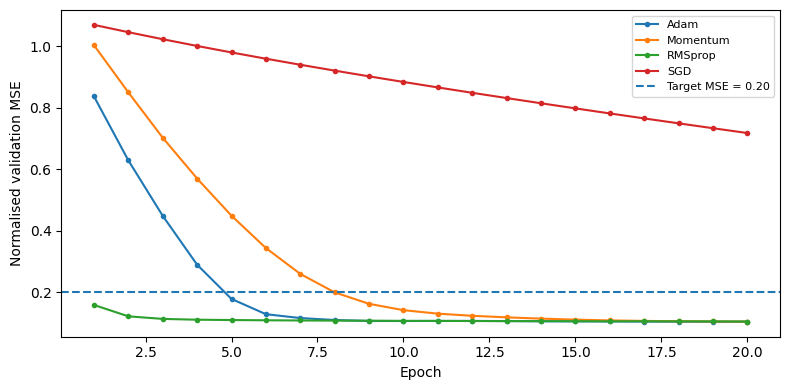


Q4 best validation configurations (mean over 3 seeds):
 optimizer  learning_rate  batch_size  epochs_to_target_mean  epochs_to_target_std  final_val_mse_mean  final_val_mse_std  test_rmse_mean  test_rmse_std  test_mae_mean  test_mae_std  loss_oscillation_std_mean  loss_oscillation_std_std  target_reach_rate
 Momentum          0.010         128                 4.6667                0.5774              0.0981             0.0047          3.6729         0.0391         2.9188        0.0697                     0.0868                    0.0059                1.0
 Momentum          0.010          32                 2.6667                0.5774              0.1003             0.0087          3.6284         0.0833         2.9849        0.1069                     0.0573                    0.0213                1.0
     Adam          0.010         128                 2.6667                0.5774              0.1010             0.0048          3.7598         0.1107         3.1183        0.0871    

,optimizer,learning_rate,batch_size,epochs_to_target_mean,epochs_to_target_std,final_val_mse_mean,final_val_mse_std,test_rmse_mean,test_rmse_std,test_mae_mean,test_mae_std,loss_oscillation_std_mean,loss_oscillation_std_std,target_reach_rate
11,Momentum,0.010,128,4.6667,0.5774,0.0981,0.0047,3.6729,0.0391,2.9188,0.0697,0.0868,0.0059,1.0
10,Momentum,0.010,32,2.6667,0.5774,0.1003,0.0087,3.6284,0.0833,2.9849,0.1069,0.0573,0.0213,1.0
5,Adam,0.010,128,2.6667,0.5774,0.1010,0.0048,3.7598,0.1107,3.1183,0.0871,0.0374,0.0095,1.0
15,RMSprop,0.001,128,2.0000,0.0000,0.1020,0.0030,3.5100,0.0407,2.8956,0.0235,0.0411,0.0177,1.0
2,Adam,0.001,32,5.0000,0.0000,0.1039,0.0054,3.5959,0.0482,2.9429,0.0617,0.0684,0.0054,1.0
22,SGD,0.010,32,7.6667,0.5774,0.1047,0.0054,3.7218,0.2584,3.0681,0.2414,0.0550,0.0021,1.0
8,Momentum,0.001,32,8.6667,0.5774,0.1048,0.0056,3.7904,0.3123,3.1229,0.2976,0.0563,0.0031,1.0
14,RMSprop,0.001,32,1.0000,0.0000,0.1051,0.0033,3.4921,0.0085,2.8839,0.0265,0.0084,0.0014,1.0
3,Adam,0.001,128,11.0000,1.0000,0.1092,0.0093,3.7163,0.1318,3.0529,0.1230,0.0395,0.0014,1.0
17,RMSprop,0.010,128,3.0000,1.0000,0.1111,0.0156,3.5201,0.1411,2.9474,0.1524,0.8259,0.1057,1.0


In [9]:
# Run Q4. If energydata_complete.csv is present beside this notebook,
# the code uses the public UCI Appliances Energy Prediction data.
q4_experiment()
q4_results = pd.read_csv(os.path.join(OUT, "q4_optimizer_aggregate.csv"))
q4_metadata = json.load(open(os.path.join(OUT, "q4_dataset_metadata.json")))
print("Dataset used:", q4_metadata)
display(q4_results.sort_values("final_val_mse_mean").head(12).round(4))

### How to interpret Q4
- `epochs_to_target` measures how quickly a setting reaches the chosen validation target. A blank/NaN value means the target was not reached within the budget.
- `test_rmse` and `test_mae` are calculated after training; lower is better.
- `loss_oscillation_std` summarises changes in validation loss; very large values or divergence indicate instability.
- Select the most reliable configuration using target reach rate and validation/test errors together. Adaptive optimisers are not immune to an excessively high learning rate.

# Q5 – Derive a Convolutional Network from a Design Principle (7 marks)

### Problem context – Printed circuit board (PCB) defect inspection
A factory camera captures PCB images. Scratches, missing components and solder bridges can occur at different image positions. A useful design principle is that visual patterns are local and the same local detector should be reused across image positions.

### Design and mathematics
A convolution applies a kernel at every valid spatial location, sharing its weights. For input height \(H\), kernel \(K\), padding \(P\) and stride \(S\):

\[
H_{out}=\left\lfloor\frac{H+2P-K}{S}\right\rfloor+1,
\qquad
W_{out}=\left\lfloor\frac{W+2P-K}{S}\right\rfloor+1.
\]

For \(C_{in}\) input channels and \(C_{out}\) filters, a convolution has

\[
N_{conv}=K_hK_wC_{in}C_{out}+C_{out}
\]

trainable parameters (including one bias per output channel). A dense first layer on a flattened 8×8 grayscale image with 32 outputs has \(64\times32+32=2,080\) parameters; a 3×3 convolution with 16 filters has \(3\times3\times1\times16+16=160\) parameters.

Pooling reduces spatial resolution and can make classification less sensitive to small local translations. It does not guarantee perfect translation invariance.

### Dataset and experiment
Use the public Digits dataset (1,797 8×8 grayscale images; stratified 60/20/20 split) as a compact image proxy, not PCB defect data. The experiment compares a flattened fully connected model with student-designed CNNs, records parameter counts, MACs, training time, test accuracy and accuracy after a one-pixel translation, and visualises first-layer filters and feature maps.

In [10]:
# Q5/Q6 CNN architecture family, params/MACs/translation test and visualisation
class SmallCNN(nn.Module):
    def __init__(self,depth=2,width=8,classes=10):
        super().__init__(); layers=[]; cin=1
        for i in range(depth):
            cout=width if i==0 else width*(2 if i>=1 else 1)
            layers += [nn.Conv2d(cin,cout,3,padding=1),nn.ReLU()]
            if i in [0,1]: layers += [nn.MaxPool2d(2)]
            cin=cout
        self.features=nn.Sequential(*layers); self.pool=nn.AdaptiveAvgPool2d(1); self.fc=nn.Linear(cin,classes)
    def forward(self,x): return self.fc(self.pool(self.features(x)).flatten(1))
class FlatMLP(nn.Module):
    def __init__(self): super().__init__(); self.net=nn.Sequential(nn.Flatten(),nn.Linear(64,128),nn.ReLU(),nn.Linear(128,10))
    def forward(self,x): return self.net(x)
def count_macs(model,input_shape):
    macs=[0]; hooks=[]
    def hook(module,inp,out):
        if isinstance(module,nn.Conv2d):
            macs[0]+=out.shape[0]*out.shape[2]*out.shape[3]*module.kernel_size[0]*module.kernel_size[1]*module.in_channels*module.out_channels
        elif isinstance(module,nn.Linear): macs[0]+=inp[0].numel()//inp[0].shape[0]*module.out_features
    for m in model.modules():
        if isinstance(m,(nn.Conv2d,nn.Linear)): hooks.append(m.register_forward_hook(hook))
    with torch.no_grad(): model(torch.zeros(*input_shape,device=DEVICE))
    for h in hooks:h.remove()
    return macs[0]
def translate(x,shift=1):
    out=torch.zeros_like(x); out[:,:,shift:,shift:]=x[:,:,:-shift,:-shift]; return out
def q5_q6_experiment():
    X,y,Xv,yv,Xte,yte=load_digits_data()
    X16=F.interpolate(X,size=(16,16),mode="bilinear",align_corners=False)
    Xv16=F.interpolate(Xv,size=(16,16),mode="bilinear",align_corners=False)
    Xte16=F.interpolate(Xte,size=(16,16),mode="bilinear",align_corners=False)
    rows=[]; visual_models={}
    for seed in [42,43,44]:
      seed_all(seed)
      models=[("FC_8x8",FlatMLP(),8),("CNN_d1_w8_8x8",SmallCNN(1,8),8),
              ("CNN_d2_w8_8x8",SmallCNN(2,8),8),("CNN_d2_w16_8x8",SmallCNN(2,16),8),
              ("CNN_d3_w8_8x8",SmallCNN(3,8),8),("CNN_d3_w16_8x8",SmallCNN(3,16),8),
              ("CNN_d2_w8_16x16",SmallCNN(2,8),16)]
      for name,model,size in models:
        model=model.to(DEVICE); opt=torch.optim.Adam(model.parameters(),lr=.002)
        xin=X if size==8 else X16; xval=Xv if size==8 else Xv16; xtest=Xte if size==8 else Xte16
        loader=DataLoader(TensorDataset(xin,y),batch_size=64,shuffle=True)
        train_start=time.perf_counter()
        for ep in range(6):
          model.train()
          for xb,yb in loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE); opt.zero_grad(); loss=nn.functional.cross_entropy(model(xb),yb); loss.backward(); opt.step()
        train_seconds=time.perf_counter()-train_start
        model.eval()
        with torch.no_grad():
          valacc=(model(xval.to(DEVICE)).argmax(1)==yv.to(DEVICE)).float().mean().item()
          acc=(model(xtest.to(DEVICE)).argmax(1)==yte.to(DEVICE)).float().mean().item()
          shiftacc=(model(translate(xtest.to(DEVICE))).argmax(1)==yte.to(DEVICE)).float().mean().item()
        params=sum(p.numel() for p in model.parameters()); macs=count_macs(model,(1,1,size,size))
        start_t=time.perf_counter()
        with torch.no_grad():
          for _ in range(10): model(xtest[:1].to(DEVICE))
        latency_ms=(time.perf_counter()-start_t)*1000/10
        path=os.path.join(OUT,name+"_seed"+str(seed)+".pt"); torch.save(model.state_dict(),path); size_bytes=os.path.getsize(path)
        rows.append(dict(seed=seed,model=name,parameters=params,estimated_macs=macs,model_file_bytes=size_bytes,
                         train_seconds=train_seconds,validation_accuracy=valacc,test_accuracy=acc,shifted_test_accuracy=shiftacc,
                         accuracy_drop=acc-shiftacc,inference_ms_per_image=latency_ms))
        if seed==42: visual_models[name]=model
    df=pd.DataFrame(rows); df.to_csv(os.path.join(OUT,"q5_q6_cnn_results.csv"),index=False)
    agg=df.groupby("model").agg({c:["mean","std"] for c in ["parameters","estimated_macs","model_file_bytes","train_seconds","validation_accuracy","test_accuracy","shifted_test_accuracy","accuracy_drop","inference_ms_per_image"]})
    agg.columns=["_".join(c) for c in agg.columns]; agg.reset_index().to_csv(os.path.join(OUT,"q5_q6_cnn_aggregate.csv"),index=False)
    cnn=visual_models["CNN_d2_w8_8x8"]; conv=next(m for m in cnn.modules() if isinstance(m,nn.Conv2d)); w=conv.weight.detach().cpu()
    fig,axs=plt.subplots(2,4,figsize=(8,4))
    for i,ax in enumerate(axs.flat): ax.imshow(w[i,0],cmap="gray"); ax.axis("off")
    savefig("q5_first_layer_filters.png")
    sample=Xte[:1].to(DEVICE); maps=None
    with torch.no_grad():
      z=sample
      for layer in cnn.features:
        z=layer(z)
        if isinstance(layer,nn.ReLU): maps=z; break
    fmap=maps[0].detach().cpu(); fig,axs=plt.subplots(2,4,figsize=(8,4))
    for i,ax in enumerate(axs.flat): ax.imshow(fmap[i],cmap="viridis"); ax.axis("off")
    savefig("q5_feature_maps.png")
    print("\nQ5/Q6 aggregate results (mean over 3 seeds):\n",agg.round(4).to_string())

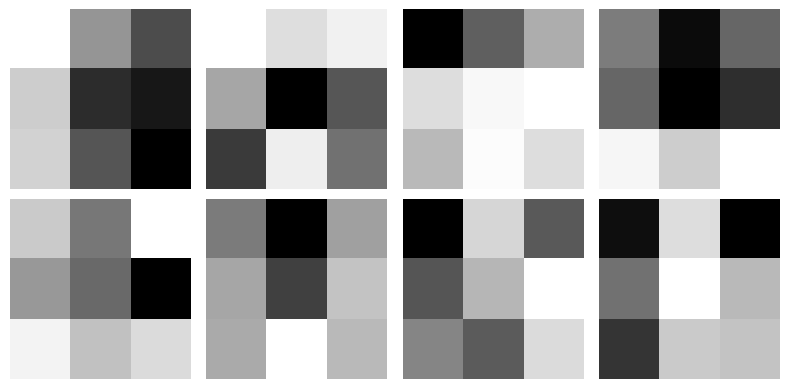

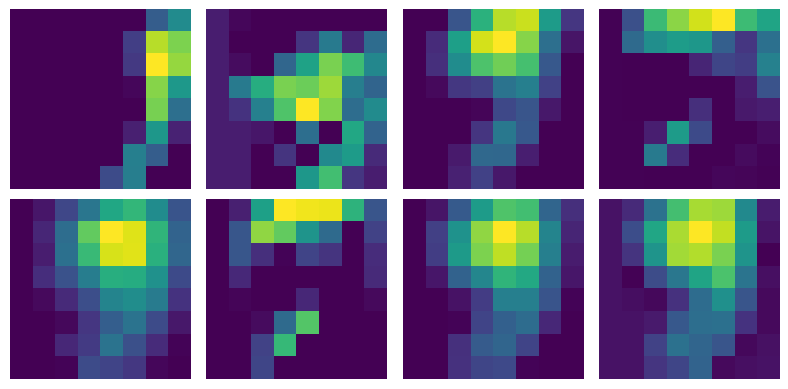


Q5/Q6 aggregate results (mean over 3 seeds):
                  parameters_mean  parameters_std  estimated_macs_mean  estimated_macs_std  model_file_bytes_mean  model_file_bytes_std  train_seconds_mean  train_seconds_std  validation_accuracy_mean  validation_accuracy_std  test_accuracy_mean  test_accuracy_std  shifted_test_accuracy_mean  shifted_test_accuracy_std  accuracy_drop_mean  accuracy_drop_std  inference_ms_per_image_mean  inference_ms_per_image_std
model                                                                                                                                                                                                                                                                                                                                                                                                                         
CNN_d1_w8_8x8              170.0             0.0               4688.0                 0.0                 3359.0           

,model,parameters_mean,estimated_macs_mean,test_accuracy_mean,shifted_test_accuracy_mean,accuracy_drop_mean,train_seconds_mean
0,CNN_d1_w8_8x8,170.0,4688.0,0.1546,0.1463,0.0083,0.6112
1,CNN_d2_w16_8x8,5130.0,83264.0,0.7222,0.2546,0.4676,0.2441
2,CNN_d2_w8_16x16,1418.0,92320.0,0.2704,0.1704,0.1000,0.2533
3,CNN_d2_w8_8x8,1418.0,23200.0,0.5565,0.1991,0.3574,0.2624
4,CNN_d3_w16_8x8,14378.0,120128.0,0.8083,0.2972,0.5111,0.2680
5,CNN_d3_w8_8x8,3738.0,32416.0,0.5954,0.2028,0.3926,0.2582
6,FC_8x8,9610.0,9472.0,0.9046,0.1407,0.7639,0.1781


In [11]:
# Run Q5 (also trains the model family needed for Q6).
q5_q6_experiment()
q5_q6_table = pd.read_csv(os.path.join(OUT, "q5_q6_cnn_aggregate.csv"))
display(q5_q6_table[["model", "parameters_mean", "estimated_macs_mean", "test_accuracy_mean",
                     "shifted_test_accuracy_mean", "accuracy_drop_mean", "train_seconds_mean"]].round(4))

### How to interpret Q5
- Compare the fully connected model and CNN using the same training/test split and epoch budget.
- A small accuracy drop after shifting an image indicates better tolerance to that particular translation, but test several shift sizes before making a broad claim.
- The first convolutional filters and feature maps show the local patterns learned by the network. Weight sharing means the same filter is evaluated at all image locations, so a learned local detector can respond at positions not tied to a fixed dense-layer input index.

# Q6 – Architecture Design: Capacity, Cost and Deployment Boundary (8 marks)

### Problem context – On-device wildlife camera trap
A battery-powered camera trap must classify elephant, deer, human or empty-scene images locally, without an internet connection. The device has memory and inference-time limits.

### What this experiment investigates
The CNN family changes **depth, width and input resolution**. The notebook records parameter count, estimated multiply–accumulate operations (MACs), checkpoint size, inference time and validation accuracy.

For a convolution layer:

\[
Parameters=K^2C_{in}C_{out}+C_{out},
\]
\[
MACs\approx H_{out}W_{out}K^2C_{in}C_{out}.
\]

One multiply-accumulate is counted as one MAC. The code's hook-based estimate also counts dense-layer MACs. Model file size is measured from the saved state dictionary and may differ from RAM usage.

Receptive field is calculated recursively. If \(r_l\) is the receptive-field width and \(j_l\) the spacing between neighbouring features in input pixels:

\[
r_l=r_{l-1}+(k_l-1)j_{l-1},\qquad j_l=j_{l-1}s_l,
\]

starting with \(r_0=j_0=1\).

### Hand calculation required by the assignment
For the 8×8, depth-2, width-8 CNN:
- Conv1: 8×8×1 → 8×8×8, 80 parameters; 4,608 MACs.
- 2×2 max-pooling: 8×8×8 → 4×4×8.
- Conv2: 4×4×8 → 4×4×16, 1,168 parameters; 18,432 MACs.
- 2×2 max-pooling: 4×4×16 → 2×2×16.
- Global average pooling: 2×2×16 → 1×1×16.
- Classifier: 16 → 10, 170 parameters.
- Total: 1,418 trainable parameters. Convolution MACs = 23,040; including the 16→10 dense classifier adds 160 MACs, giving 23,200 by the notebook's counting convention.

The data are the Digits proxy, not actual wildlife images. Deployment conclusions are therefore illustrative and must be revalidated on the camera-trap dataset and target hardware.

In [12]:
# Q6 helper: receptive field calculation for sequential kernel/stride operations.
def receptive_field(operations):
    """operations is a list of (kernel_size, stride) pairs."""
    rf, jump = 1, 1
    rows = []
    for layer_no, (kernel, stride) in enumerate(operations, start=1):
        rf = rf + (kernel - 1) * jump
        jump = jump * stride
        rows.append({"operation": layer_no, "kernel": kernel, "stride": stride,
                     "receptive_field": rf, "jump": jump})
    return pd.DataFrame(rows)

def hand_check_small_cnn():
    """Hand-check the depth=2, width=8 CNN on a 1x8x8 image."""
    # Conv1: 3x3, 1 input channel, 8 output channels, bias included.
    conv1_params = 3 * 3 * 1 * 8 + 8
    # After 2x2 pooling: 8x8x8 -> 4x4x8.
    # Conv2: 3x3, 8 input channels, 16 output channels, bias included.
    conv2_params = 3 * 3 * 8 * 16 + 16
    # Global average pooling gives 16 features; classifier maps 16 -> 10.
    classifier_params = 16 * 10 + 10
    total = conv1_params + conv2_params + classifier_params
    model = SmallCNN(depth=2, width=8).to(DEVICE)
    framework_total = sum(p.numel() for p in model.parameters())
    example = torch.zeros(1, 1, 8, 8, device=DEVICE)
    with torch.no_grad():
        feature_shape = tuple(model.features(example).shape)
        pooled_shape = tuple(model.pool(model.features(example)).shape)
        logits_shape = tuple(model(example).shape)
    result = {
        "conv1_parameters": conv1_params,
        "conv2_parameters": conv2_params,
        "classifier_parameters": classifier_params,
        "hand_calculated_total": total,
        "framework_parameter_total": framework_total,
        "feature_shape_after_conv_pool_stack": feature_shape,
        "shape_after_global_average_pool": pooled_shape,
        "classifier_output_shape": logits_shape,
    }
    assert total == framework_total, f"Parameter mismatch: hand={total}, framework={framework_total}"
    assert feature_shape == (1, 16, 2, 2)
    return pd.Series(result)

In [13]:
# Run the hand-verified example and receptive-field calculation.
hand_check = hand_check_small_cnn()
print("Hand calculation / framework cross-check:")
display(hand_check)

# Two 3x3 conv layers (stride 1) separated/followed by 2x2 pooling (stride 2).
rf_table = receptive_field([(3, 1), (2, 2), (3, 1), (2, 2)])
print("Receptive-field growth through conv/pooling operations:")
display(rf_table)

Hand calculation / framework cross-check:


,0
conv1_parameters,80
conv2_parameters,1168
classifier_parameters,170
hand_calculated_total,1418
framework_parameter_total,1418
feature_shape_after_conv_pool_stack,"(1, 16, 2, 2)"
shape_after_global_average_pool,"(1, 16, 1, 1)"
classifier_output_shape,"(1, 10)"


Receptive-field growth through conv/pooling operations:


,operation,kernel,stride,receptive_field,jump
0,1,3,1,3,1
1,2,2,2,4,2
2,3,3,1,8,2
3,4,2,2,10,4


In [14]:
# Inspect the architecture family measurements created by Q5/Q6.
q6_metrics = pd.read_csv(os.path.join(OUT, "q5_q6_cnn_aggregate.csv"))
display(q6_metrics[["model", "parameters_mean", "estimated_macs_mean", "model_file_bytes_mean",
                    "inference_ms_per_image_mean", "validation_accuracy_mean"]].round(4))

# Example deployment boundary; adjust only when you have a real device specification.
MEMORY_BUDGET_BYTES = 1_000_000  # 1 MB checkpoint budget (illustrative)
LATENCY_BUDGET_MS = 10.0          # 10 ms per image (illustrative)
eligible = q6_metrics[(q6_metrics.model_file_bytes_mean <= MEMORY_BUDGET_BYTES) &
                      (q6_metrics.inference_ms_per_image_mean <= LATENCY_BUDGET_MS)]
if len(eligible):
    selected = eligible.sort_values("validation_accuracy_mean", ascending=False).iloc[0]
    largest = q6_metrics.sort_values("parameters_mean", ascending=False).iloc[0]
    print("Selected model under the illustrative budget:", selected["model"])
    print("Accuracy difference vs largest model:",
          round(float(largest["validation_accuracy_mean"] - selected["validation_accuracy_mean"]), 4))
else:
    print("No model met both illustrative constraints on this hardware. Relax or revise the budget based on a real device.")

,model,parameters_mean,estimated_macs_mean,model_file_bytes_mean,inference_ms_per_image_mean,validation_accuracy_mean
0,CNN_d1_w8_8x8,170.0,4688.0,3359.0,0.2478,0.1681
1,CNN_d2_w16_8x8,5130.0,83264.0,23933.0,0.3313,0.7493
2,CNN_d2_w8_16x16,1418.0,92320.0,9097.0,0.3375,0.2563
3,CNN_d2_w8_8x8,1418.0,23200.0,9009.0,0.3381,0.5599
4,CNN_d3_w16_8x8,14378.0,120128.0,61521.0,0.3987,0.8115
5,CNN_d3_w8_8x8,3738.0,32416.0,18883.0,0.4177,0.6007
6,FC_8x8,9610.0,9472.0,41049.0,0.1363,0.9229


Selected model under the illustrative budget: FC_8x8
Accuracy difference vs largest model: -0.1114


### How to interpret Q6
- Doubling width in every layer can make the dominant convolution term grow roughly quadratically because it includes \(C_{in}C_{out}\). Doubling depth often grows cost roughly linearly when the added layers have similar channel counts and feature-map sizes.
- Doubling both image height and width creates approximately four times as many spatial positions, so MACs can grow about fourfold when other factors are fixed.
- The deployment limits in the code (1 MB and 10 ms) are **illustrative assumptions**, not measured specifications for a named camera. Use inference timing on the actual target device before defending a deployment choice.

# Q7 – Diagnose, Redesign and Validate (13 marks)

### Problem context – Day-4 design challenge
Review evidence from Q1–Q6 and select one model with a measurable limitation. This notebook focuses on **vanishing gradients in an eight-hidden-layer sigmoid MLP**. The redesign is not a replacement with a famous architecture; it changes the hidden activation and initialisation while keeping depth and width unchanged.

### A. Diagnose the bottleneck
The expected cause is repeated multiplication by sigmoid derivatives. Since \(\sigma'(z)\leq0.25\), repeated saturated activations can make early-layer gradients very small. The code records the first and last hidden-layer gradient norms during the first training mini-batch.

### B. Define a measurable objective
Prospective objective: increase the first-layer gradient norm by at least 10× relative to the original eight-layer sigmoid network, while preserving or improving validation performance under the same data split, seeds, optimiser and epoch budget. This target must be evaluated from the generated comparison; it is not assumed to be achieved.

### C. Redesigned model
- Original: 8 hidden layers × 64 units, Sigmoid, Xavier initialisation.
- Redesigned: 8 hidden layers × 64 units, ReLU, He initialisation.
- Same output sigmoid, binary cross-entropy, Adam learning rate 0.001, batch size 32 and 15 epochs.

ReLU has derivative 1 on active units, and He initialisation uses \(Var(W)=2/fan_{in}\). This should improve gradient flow on active paths. Trade-off: inactive ReLU units are possible and must be monitored.

### D–F. Predict, validate and defend
Prediction: the redesigned network should increase early-layer gradient magnitude. Compare gradient norms, validation loss, accuracy, precision, recall and parameter count across three seeds. If gradients improve but validation accuracy does not, conclude that gradient flow improved but was not the only performance bottleneck.

### Dataset
The experiment uses the same 569-row Wisconsin Breast Cancer tabular proxy and the same 60/20/20 split as Q1. It is not an actual credit-card fraud dataset; the redesign principle should be revalidated on real transaction data.

In [15]:
# Q7: original deep sigmoid vs redesigned deep ReLU + He under matched conditions
def q7_redesign_experiment():
    X,y,Xv,yv,Xte,yte=load_bc()
    rows=[]; curves=[]
    for seed in [42,43,44]:
      for name,act in [("original_sigmoid","sigmoid"),("redesigned_relu_he","relu")]:
        seed_all(seed); model=MLP(X.shape[1],64,8,act,None).to(DEVICE)
        opt=torch.optim.Adam(model.parameters(),lr=.001); loader=DataLoader(TensorDataset(X,y),batch_size=32,shuffle=True)
        first_grad=None; last_grad=None
        for ep in range(1,16):
          model.train()
          for xb,yb in loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE); opt.zero_grad(); pred=model(xb)
            loss=nn.functional.binary_cross_entropy(pred,yb); loss.backward()
            if first_grad is None:
              norms=grad_norms(model); first_grad=norms[0] if norms else np.nan; last_grad=norms[-1] if norms else np.nan
            opt.step()
          model.eval()
          with torch.no_grad():
            trp=model(X.to(DEVICE)).cpu().numpy().ravel()
            vp=model(Xv.to(DEVICE)).cpu().numpy().ravel()
            trloss=float(nn.functional.binary_cross_entropy(torch.tensor(trp[:,None]),y))
            vloss=float(nn.functional.binary_cross_entropy(torch.tensor(vp[:,None]),yv))
          curves.append(dict(seed=seed,model=name,epoch=ep,train_loss=trloss,val_loss=vloss))
        with torch.no_grad():
          vp=model(Xv.to(DEVICE)).cpu().numpy().ravel()
        rows.append(dict(seed=seed,model=name,first_layer_gradient_norm=first_grad,
          last_hidden_gradient_norm=last_grad,gradient_ratio_first_to_last=first_grad/(last_grad+1e-12),
          validation_accuracy=accuracy_score(yv.numpy().ravel(),vp>=.5),
          validation_precision=precision_score(yv.numpy().ravel(),vp>=.5,zero_division=0),
          validation_recall=recall_score(yv.numpy().ravel(),vp>=.5,zero_division=0),
          parameter_count=sum(p.numel() for p in model.parameters())))
    df=pd.DataFrame(rows); df.to_csv(os.path.join(OUT,"q7_redesign_comparison.csv"),index=False)
    cdf=pd.DataFrame(curves); cdf.to_csv(os.path.join(OUT,"q7_learning_curves.csv"),index=False)
    plt.figure(figsize=(8,4))
    for name,g in cdf.groupby("model"):
      mean=g.groupby("epoch").val_loss.mean()
      plt.plot(mean.index,mean.values,label=name)
    plt.xlabel("Epoch"); plt.ylabel("Validation BCE"); plt.legend(); savefig("q7_redesign_validation_loss.png")
    print("\\nQ7 redesign comparison saved.")

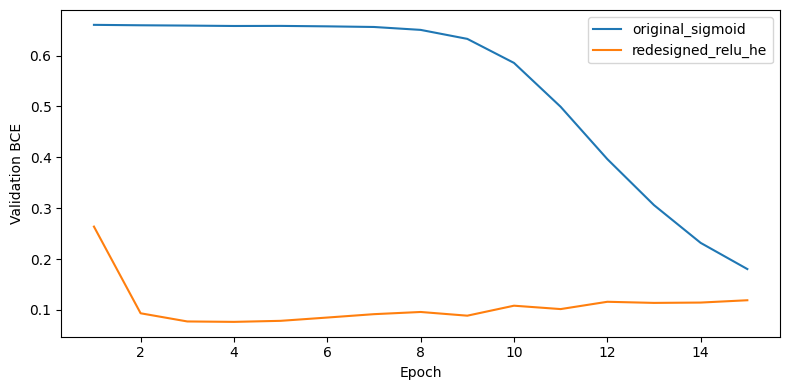

\nQ7 redesign comparison saved.


first_layer_gradient_norm            \
                                        mean       std   
model                                                    
original_sigmoid                    0.000010  0.000001   
redesigned_relu_he                  0.482112  0.210443   

                   last_hidden_gradient_norm           validation_accuracy  \
                                        mean       std                mean   
model                                                                        
original_sigmoid                    0.077396  0.070805            0.964912   
redesigned_relu_he                  1.001124  0.624999            0.964912   

                             validation_precision           validation_recall  \
                         std                 mean       std              mean   
model                                                                           
original_sigmoid    0.008772             0.976716  0.007802          0.967593   
redesigned_relu_he  0.015193             0.981221  0.016263          0.962963   

                             parameter_count  
                         std            mean  
model                                         
original_sigmoid    0.016038         31169.0  
redesigned_relu_he  0.008019         31169.0

In [16]:
# Run Q7: compare original and redesigned models under matched conditions.
q7_redesign_experiment()
q7_results = pd.read_csv(os.path.join(OUT, "q7_redesign_comparison.csv"))
display(q7_results.groupby("model").agg({
    "first_layer_gradient_norm":["mean", "std"],
    "last_hidden_gradient_norm":["mean", "std"],
    "validation_accuracy":["mean", "std"],
    "validation_precision":["mean", "std"],
    "validation_recall":["mean", "std"],
    "parameter_count":["mean"]
}).round(6))

### Q7 conclusion template
After the run, fill in the actual numbers:
1. The original model's mean first-layer gradient norm was ______.
2. The redesigned model's mean first-layer gradient norm was ______.
3. The improvement factor was ______×.
4. Validation accuracy changed from ______ to ______.
5. The redesign did / did not meet the predeclared 10× gradient objective.
6. The redesign's main trade-off was ______.

A redesign is not automatically unsuccessful if it fails to outperform the original. Explain what the evidence shows, including any new limitation, rather than changing the success criterion after seeing the result.

## 8. Run all questions (optional)

The notebook is also organised so each question can be run independently. Use this final cell only when you want to regenerate every CSV, plot and model checkpoint in one session. It runs all experiments in sequence and may take several minutes, especially on CPU.

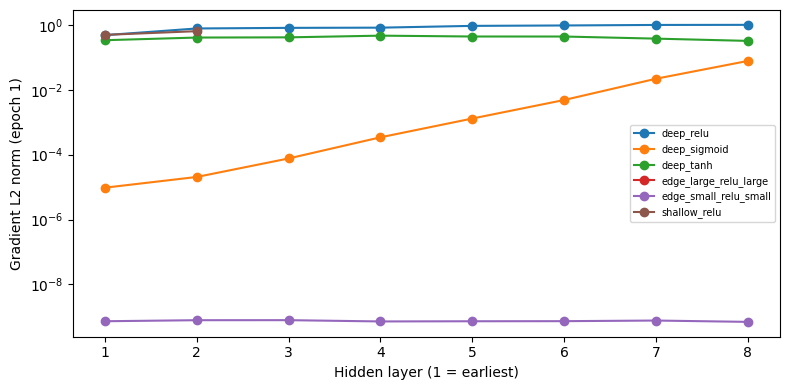


Q1 results saved.

Q2 gradient check:
  buggy_backward  epsilon parameter  relative_error
          False 0.000010        W1    3.319988e-10
          False 0.000010        b1    2.297381e-10
          False 0.000010        W2    4.127400e-11
          False 0.000010        b2    3.704433e-12
          False 0.000001        W1    3.088239e-09
          False 0.000001        b1    9.022106e-09
          False 0.000001        W2    1.676180e-10
          False 0.000001        b2    3.825897e-10
           True 0.000010        W1    6.222739e-01
           True 0.000010        b1    6.412649e-01
           True 0.000010        W2    4.127400e-11
           True 0.000010        b2    3.704433e-12
           True 0.000001        W1    6.222739e-01
           True 0.000001        b1    6.412649e-01
           True 0.000001        W2    1.676180e-10
           True 0.000001        b2    3.825897e-10
NumPy-only training runs:\n  seed                                                         dat

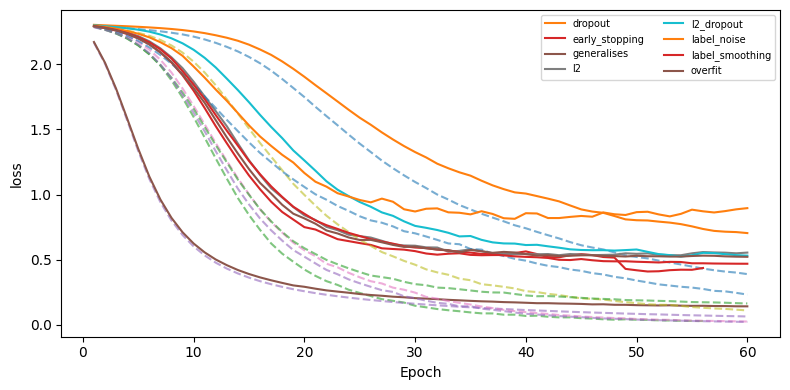

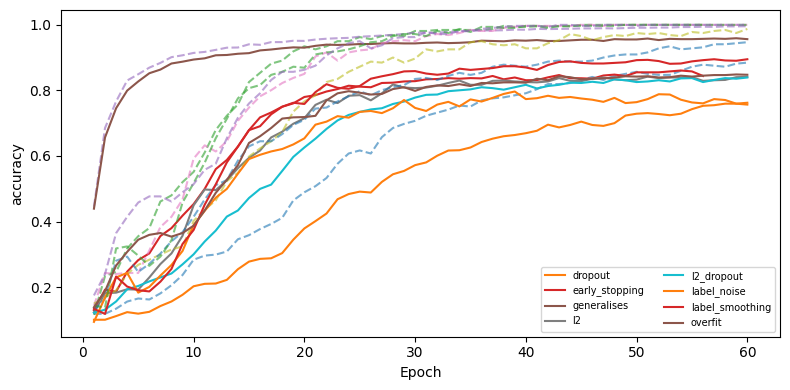


Q3 aggregate results:
                  best_val_loss_mean  best_val_loss_std  best_epoch_mean  best_epoch_std  epochs_run_mean  epochs_run_std  train_accuracy_mean  train_accuracy_std  val_accuracy_mean  val_accuracy_std  accuracy_gap_mean  accuracy_gap_std  test_accuracy_mean  test_accuracy_std  weight_l2_norm_mean  weight_l2_norm_std
condition                                                                                                                                                                                                                                                                                                                  
dropout                      0.6992             0.1808          59.0000          1.7321             60.0             0.0               0.8785              0.0809             0.7586            0.1001             0.1199            0.0288              0.7546             0.0863              13.3921              0.2535
early_stopping              

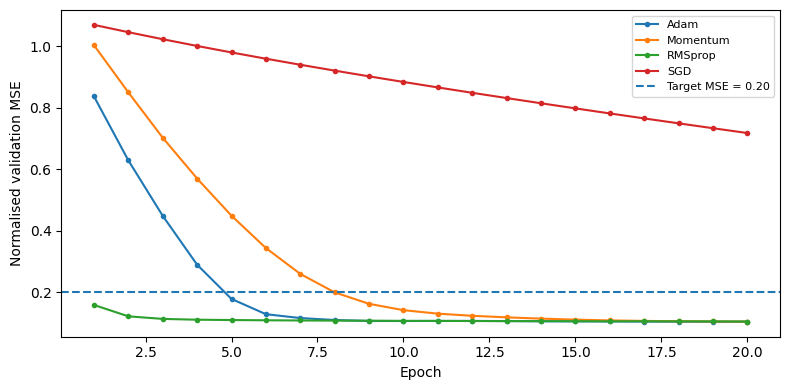


Q4 best validation configurations (mean over 3 seeds):
 optimizer  learning_rate  batch_size  epochs_to_target_mean  epochs_to_target_std  final_val_mse_mean  final_val_mse_std  test_rmse_mean  test_rmse_std  test_mae_mean  test_mae_std  loss_oscillation_std_mean  loss_oscillation_std_std  target_reach_rate
 Momentum          0.010         128                 4.6667                0.5774              0.0981             0.0047          3.6729         0.0391         2.9188        0.0697                     0.0868                    0.0059                1.0
 Momentum          0.010          32                 2.6667                0.5774              0.1003             0.0087          3.6284         0.0833         2.9849        0.1069                     0.0573                    0.0213                1.0
     Adam          0.010         128                 2.6667                0.5774              0.1010             0.0048          3.7598         0.1107         3.1183        0.0871    

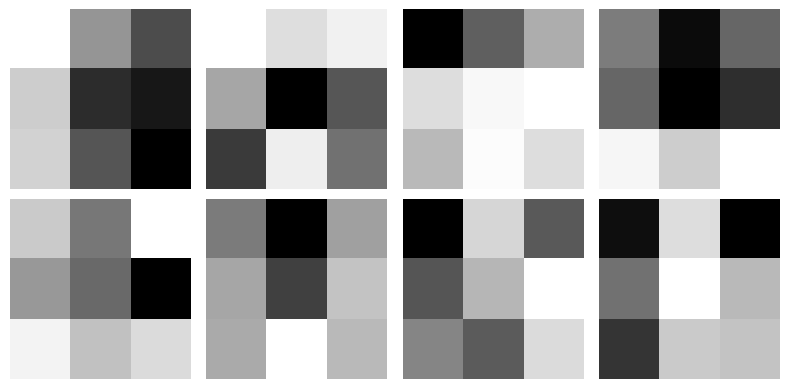

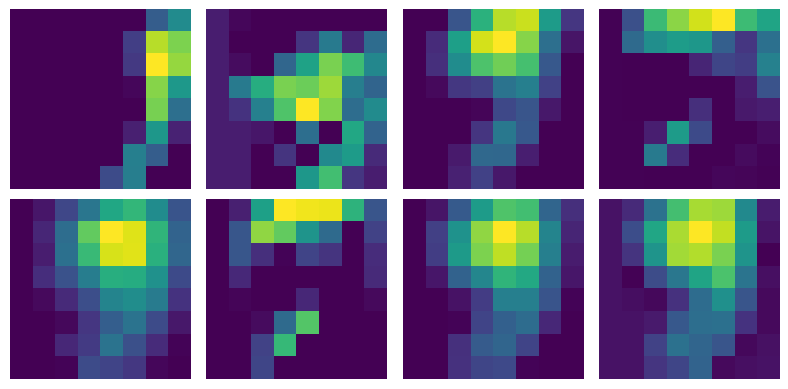


Q5/Q6 aggregate results (mean over 3 seeds):
                  parameters_mean  parameters_std  estimated_macs_mean  estimated_macs_std  model_file_bytes_mean  model_file_bytes_std  train_seconds_mean  train_seconds_std  validation_accuracy_mean  validation_accuracy_std  test_accuracy_mean  test_accuracy_std  shifted_test_accuracy_mean  shifted_test_accuracy_std  accuracy_drop_mean  accuracy_drop_std  inference_ms_per_image_mean  inference_ms_per_image_std
model                                                                                                                                                                                                                                                                                                                                                                                                                         
CNN_d1_w8_8x8              170.0             0.0               4688.0                 0.0                 3359.0           

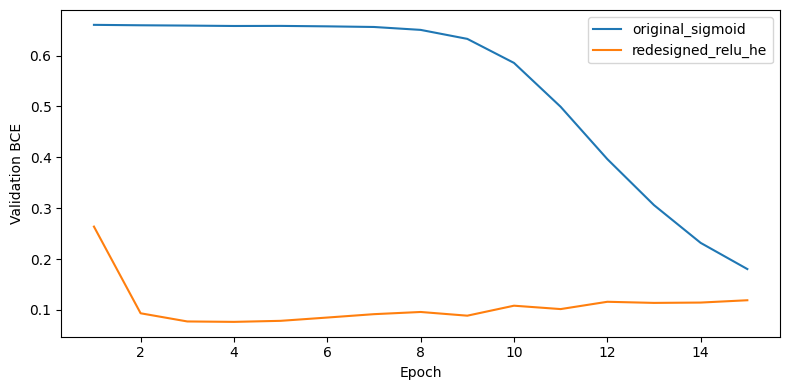

\nQ7 redesign comparison saved.
All requested experiment functions finished.
Results folder: /content/dl_assignment2_results


In [17]:
# Optional full run. Comment out any question you do not want to rerun.
q1_experiment()
gradient_check()
q3_experiment()
q4_experiment()
q5_q6_experiment()
hand_check_small_cnn()
q7_redesign_experiment()

print("All requested experiment functions finished.")
print("Results folder:", os.path.abspath(OUT))

## 9. Output files created

| Question | Main output files |
|---|---|
| Q1 | `q1_activation_results.csv`, `q1_gradient_norms.csv`, `q1_gradient_norms.png` |
| Q2 | `q2_gradient_check.csv`, `q2_numpy_training_summary.csv`, `q2_numpy_training_curve.csv` |
| Q3 | `q3_regularization_aggregate.csv`, `q3_learning_curves.csv`, `q3_loss_curves.png`, `q3_accuracy_curves.png` |
| Q4 | `q4_optimizer_aggregate.csv`, `q4_optimizer_results.csv`, `q4_learning_curves.csv`, `q4_dataset_metadata.json`, `q4_optimizer_curves.png` |
| Q5/Q6 | `q5_q6_cnn_aggregate.csv`, model checkpoints, `q5_first_layer_filters.png`, `q5_feature_maps.png` |
| Q7 | `q7_redesign_comparison.csv`, `q7_learning_curves.csv`, `q7_redesign_validation_loss.png` |

### Final submission checks
- Replace proxy datasets with the faculty-approved application datasets wherever required.
- State exact dataset size and train/validation/test split in every question's final report.
- Keep the saved CSVs and plots as raw experimental evidence.
- Report mean ± standard deviation for repeated runs.
- Do not present synthetic Q4 data as a public UCI dataset result.
- Be ready to explain each gradient equation, parameter count, MAC estimate and design decision during the viva.